# Comparing methods for classifying word sense definitions


The task is to classify **word senses** into coarse semantic categories named "**supersenses**" and "**hypersenses**".

The word senses will be represented using their **lemma** and their **definition**.

The objective is to explore several ways of using LLMs for this task.


## Data

We will use a dataset of manually labeled word senses [(Angleraud et al., 2024)](https://aclanthology.org/2025.coling-main.356/).

These word senses were labeled with a "supersense", each supersense corresponding to a broader "hypersense" (the taxonomy was defined by [Barque et al., 2020](https://aclanthology.org/2020.lrec-1.724/)).

In [ ]:

def download_and_load_tsv_gz(url):
  """Downloads a gzipped TSV file and loads it into a pandas DataFrame.
  Args:
    url: The URL of the gzipped TSV file.

  Returns:
    A pandas DataFrame containing the data from the file.
  """
  filename = url.split('/')[-1]
  if not os.path.exists(filename):
    !wget "$url"
  else:
    print(f"File '{filename}' already exists. Skipping download.")

  with gzip.open(filename, 'rt', encoding='utf-8') as f:
    df = pd.read_csv(f, sep='\t')

  return df


url = 'http://www.linguist.univ-paris-diderot.fr/~mcandito/divers/super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz'

try:
  df = download_and_load_tsv_gz(url)
  print("DataFrame loaded successfully.")
  print(df.head())  # Display the first few rows
except Exception as e:
  print(f"Error loading DataFrame: {e}")

File 'super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz' already exists. Skipping download.
DataFrame loaded successfully.
                    sense_id              entry_id         lemma  \
0      ws_1_esquerme__nom__1      esquerme__nom__1      esquerme   
1    ws_1_béruguette__nom__1    béruguette__nom__1    béruguette   
2  ws_2_agroécologie__nom__1  agroécologie__nom__1  agroécologie   
3     ws_1_webcaméra__nom__1     webcaméra__nom__1     webcaméra   
4     ws_1_Reguinois__nom__1     Reguinois__nom__1     Reguinois   

   nb_occ_lemma_frsemcor supersense        set  \
0                      0      plant  rand-test   
1                      0       food   rand-dev   
2                      0        act  rand-test   
3                      0   artifact  rand-test   
4                      0     person   rand-dev   

                                          definition  
0                                   Plante potagère.  
1            Variété d’olive allongée à pulpe

In [ ]:
for i in range(10):
  print("lemma:")
  print(df["lemma"][i])
  print("definition:")
  print(df["definition"][i])
  print("supersense:")
  print(df["supersense"][i])
  print()

lemma:
esquerme
definition:
Plante potagère.
supersense:
plant

lemma:
béruguette
definition:
Variété d’olive allongée à pulpe ferme.
supersense:
food

lemma:
agroécologie
definition:
Pratique ou mode de production agricole appliquant les principes de l’agroécologie.
supersense:
act

lemma:
webcaméra
definition:
Synonyme de webcam.
supersense:
artifact

lemma:
Reguinois
definition:
Habitant de Réguiny, commune française située dans le département du Morbihan.
supersense:
person

lemma:
réducteur_de_portance
definition:
Dispositif aérodynamique provoquant une diminution de la portance d’une voilure ou de la poussée d’un réacteur ou d’un moteur-fusée.
supersense:
artifact

lemma:
Saint-Hippolytaise
definition:
Habitante de Saint-Hippolyte-de-Montaigu, commune française située dans le département du Gard.
supersense:
person

lemma:
Mardésien
definition:
Habitant de Mardié, commune française située dans le département du Loiret.
supersense:
person

lemma:
butan-1-ol
definition:
Alcool prim

### Distribution of supersenses

<Axes: xlabel='supersense'>

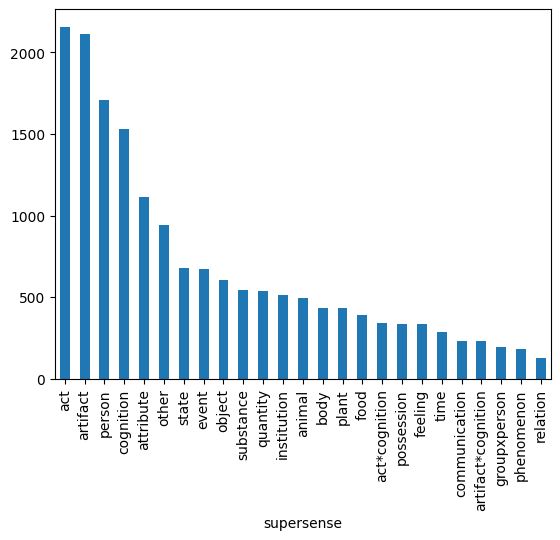

In [ ]:
df['supersense'].value_counts().plot(kind='bar')

### Distribution of hypersenses

In [ ]:
supersenses = df['supersense'].unique()
super2hyper = {'artifact': 'inanimate',
               'body': 'inanimate',
               'food': 'inanimate',
               'object': 'inanimate',
               'plant': 'inanimate',
               'substance': 'inanimate',
               'act':  'dynamic_situation',
               'event': 'dynamic_situation',
               'phenomenon': 'dynamic_situation',
               'animal': 'animate',
               'person': 'animate',
               'groupxperson': 'animate',
               'cognition': 'information',
               'communication': 'information',
               'quantity': 'quantity',
               'attribute': 'stative_situation',
               'feeling': 'stative_situation',
               'relation': 'stative_situation',
               'state': 'stative_situation',
               'time': 'time',
               'possession': 'possession',
               'institution': 'institution',
               'act*cognition': 'dynamic_situation*information',
               'artifact*cognition': 'inanimate*information',
               'other': 'other',
               }


<Axes: xlabel='hypersense'>

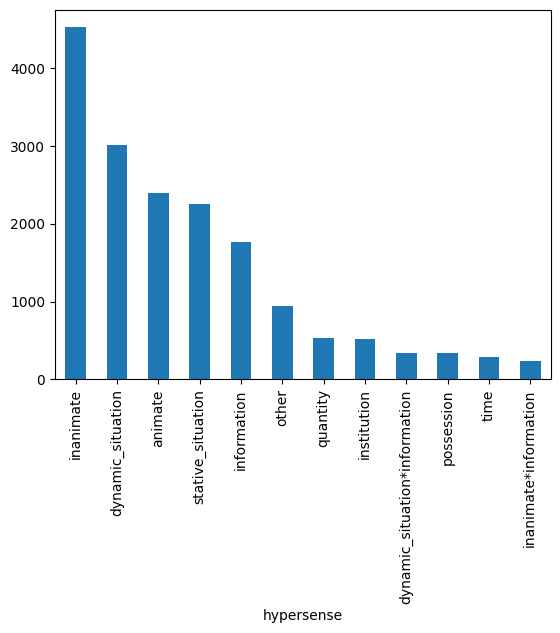

In [ ]:
df['hypersense'] = df['supersense'].map(super2hyper)
df['hypersense'].value_counts().plot(kind='bar')

### Distribution of labels across the data subsets (splits)

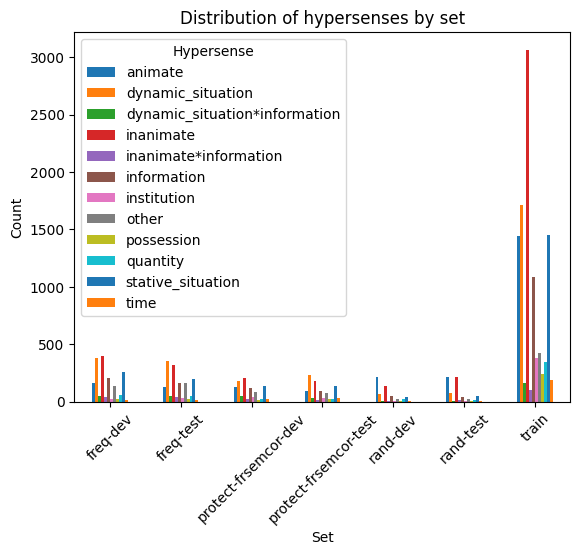

In [ ]:
# PB: note the distribution in the training set, dev and test sets are quite different

df.groupby('set')['hypersense'].value_counts().unstack().plot(kind='bar')
plt.title('Distribution of hypersenses by set')
plt.xlabel('Set')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Hypersense')
plt.show()

# Imports and data preparation

In [ ]:
# Run 'pip install -q --upgrade transformers accelerate bitsandbytes trl peft datasets'
# once in the Colab runtime before executing the imports below.

# Library imports
import copy
import gc
import glob
import gzip
import json
import os
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from google.colab import drive
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm
from transformers import (
    AutoConfig,
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
)
from trl import SFTConfig, SFTTrainer

# Persist predictions, metrics, and LoRA adapter weights to Google Drive so experiments that
# take long to run survive Colab disconnects without needing to be recomputed.
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive", force_remount=True)

# In case drive fails
assert os.path.ismount("/content/drive"), "Drive is NOT mounted, re-run this cell"
assert os.path.isdir("/content/drive/MyDrive"), "MyDrive folder not found, wrong account?"
print("Drive OK")

Mounted at /content/drive
Drive OK


In [ ]:
# Config
MODEL_NAME   = "unsloth/Qwen2.5-7B-Instruct-bnb-4bit"
DRIVE        = "/content/drive/MyDrive"
OUT_DIR      = f"{DRIVE}/lab1_icl"
OUT_DIR_PEFT = f"{DRIVE}/lab1_peft"
N_DEV        = 300
MAX_LEN      = 192
for d in (OUT_DIR, OUT_DIR_PEFT):
    os.makedirs(d, exist_ok=True)

In [ ]:
# Preparing the data

# Discard 'protect-frsemcor' splits as required by lab instructions
df = df[~df["set"].str.startswith("protect-frsemcor")].copy() # take out the protect-frsemcor part
print(df["set"].value_counts())

# Isolate splits to prevent data leakage
splits = {name: g.reset_index(drop=True) for name, g in df.groupby("set")}
train = splits["train"]
dev = splits["rand-dev"] # used for tuning decisions
# splits["freq-test"], splits["rand-test"]: final evaluation only

LABELS = sorted(df["hypersense"].unique())
print(LABELS)

# Fixed dev subset: every configuration is evaluated on exactly the same items
DEV_SUB = dev.sample(N_DEV, random_state=0).reset_index(drop=True)


set
train        10604
freq-dev      1760
freq-test     1521
rand-test      678
rand-dev       570
Name: count, dtype: int64
['animate', 'dynamic_situation', 'dynamic_situation*information', 'inanimate', 'inanimate*information', 'information', 'institution', 'other', 'possession', 'quantity', 'stative_situation', 'time']


# Loading the model

In [ ]:
# Load the 4-bit model in float16 for inference (T4 GPUs do not support bfloat16)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, device_map="auto", dtype=torch.float16
)
model.eval()
print(f"{model.get_memory_footprint() / 1e9:.1f} GB")

config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.36k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

5.4 GB


# Method 1: ICL

## Building the prompts

In [ ]:
# Translate technical supersense notation into plain English so the model can interpret
# combined and group categories when descriptions are included in the system prompt
READABLE = {
    "groupxperson": "group of people",
    "act*cognition": "both an act and its informational content",
    "artifact*cognition": "both a physical object and its informational content",
}

# Automatically derive hypersense descriptions from the supersenses they group in super2hyper
LABEL_DESC_AUTO = {
    hyper: ", ".join(READABLE.get(s, s) for s, h in super2hyper.items() if h == hyper)
    for hyper in LABELS
}

# Map string keys to description dictionaries so experimental configs remain serializable in CSVs
DESCS = {"auto": LABEL_DESC_AUTO, "none": None}

In [ ]:
def format_item(row, use_lemma=True):
    """Format a word sense into a standardized user-turn string. Allows turning off the lemma."""
    if use_lemma:
        return f"Lemma: {row['lemma']}\nDefinition: {row['definition']}"
    return f"Definition: {row['definition']}"

def sample_demos(k, seed=0):
    """Sample k demonstrations from train split, cycling over labels so that each label
    appears before any label repeats (stratified sampling), then shuffled."""
    rng = random.Random(seed)
    by_label = {lab: train[train["hypersense"] == lab] for lab in LABELS}
    demos, i = [], 0
    while len(demos) < k:
        pool = by_label[LABELS[i % len(LABELS)]]
        demos.append(pool.iloc[rng.randrange(len(pool))])
        i += 1
    rng.shuffle(demos)
    return demos

# Compare English vs. French system instructions
# Category names remain in English in both templates to match the gold label space
INSTRUCTIONS = {
    "en": ("You classify French word senses into coarse semantic categories.\n"
           "Possible categories:\n{labels}\n"
           "Answer with the category name only."),
    "fr": ("Tu classes des sens de mots français dans de grandes catégories sémantiques.\n"
           "Catégories possibles :\n{labels}\n"
           "Réponds uniquement avec le nom de la catégorie."),
}


def system_prompt(desc="auto", lang="en"):
    """Build the system instruction listing all 12 hypersenses, optionally with descriptions"""
    d = DESCS[desc]
    labels = "\n".join(f"- {lab}: {d[lab]}" if d else f"- {lab}" for lab in LABELS)
    return INSTRUCTIONS[lang].format(labels=labels)


def build_prefix(demos, demo_labels, use_lemma=True, desc="auto", lang="en"):
    """Construct the static chat prefix (system prompt + k demonstrations) shared across a run.
    Accepts `demo_labels` separately from `demos` so labels can be randomized to test
    whether ICL relies on true input-label mappings (Min et al., 2022)."""
    msgs = [{"role": "system", "content": system_prompt(desc, lang)}]
    for d, lab in zip(demos, demo_labels):
        msgs.append({"role": "user", "content": format_item(d, use_lemma)})
        msgs.append({"role": "assistant", "content": lab})
    return msgs


def build_messages(row, prefix, use_lemma=True):
    """Append the target word sense query to the shared chat prefix"""
    return prefix + [{"role": "user", "content": format_item(row, use_lemma)}]

In [ ]:
# Append Qwen's end of turn token to every candidate label during log-probability scoring,
# so prefix labels (like 'inanimate') are not unfairly favored over
# longer combined labels (like 'inanimate*information').
END_OF_TURN = "<|im_end|>"


## Inference Methods

### Log-Probability Scoring with KV Caching

In [ ]:
# Pre-tokenize all 12 candidate labels (with end-of-turn token) once to speed up scoring
CAND_IDS = [tokenizer(lab + END_OF_TURN, add_special_tokens=False).input_ids for lab in LABELS]


def prompt_ids(messages, add_generation_prompt):
    """Render chat messages via the model's template and return raw token IDs"""
    text = tokenizer.apply_chat_template(
        messages, add_generation_prompt=add_generation_prompt, tokenize=False)
    return tokenizer(text, add_special_tokens=False).input_ids


@torch.no_grad()
def encode_prefix(prefix):
    """Run the shared prefix (instruction + demos) once and keep its KV cache.
    Every item of a run reuses it, so only the query and the labels are computed per item."""
    ids = prompt_ids(prefix, add_generation_prompt=False)
    out = model(input_ids=torch.tensor([ids], device=model.device), use_cache=True, logits_to_keep=1)
    return ids, out.past_key_values

def truncate_cache(cache, target_len):
    """Cut the KV cache back to `target_len` tokens (works with old and new transformers)."""
    extra = cache.get_seq_length() - target_len
    if extra > 0:
        cache.crop(-extra)      # negative value = number of tokens to remove

@torch.no_grad()
def score_labels(messages, prefix_ids, cache, length_norm=False):
    """Return log P(label | prompt) for every label, reusing the cached prefix."""
    ids = prompt_ids(messages, add_generation_prompt=True)
    assert ids[:len(prefix_ids)] == prefix_ids, "prompt does not start with the cached prefix"
    n_prefix, n_prompt = len(prefix_ids), len(ids)
    try:
        # 1) read the query on top of the prefix; its last position predicts the 1st label token
        out = model(input_ids=torch.tensor([ids[n_prefix:]], device=model.device),
                    past_key_values=cache, use_cache=True, logits_to_keep=1)
        first = torch.log_softmax(out.logits[0, -1].float(), dim=-1)

        scores = []
        for c in CAND_IDS:
            lps = [first[c[0]]]
            if len(c) > 1:
                # 2) feed the label tokens; position j predicts token j+1
                o = model(input_ids=torch.tensor([c[:-1]], device=model.device),
                          past_key_values=cache, use_cache=True)
                step = torch.log_softmax(o.logits[0].float(), dim=-1)
                lps += [step[j, c[j + 1]] for j in range(len(c) - 1)]
                truncate_cache(cache, n_prompt) # remove this label, keep the prompt
            lp = torch.stack(lps)
            scores.append((lp.mean() if length_norm else lp.sum()).item())
        return scores
    finally:
        truncate_cache(cache, n_prefix) # remove the query: back to the shared prefix

### Standard Text Generation with Validity Checking

In [ ]:
@torch.no_grad()
def generate_label(messages):
    """Predict a label via greedy decoding and flag out-of-vocabulary outputs as 'INVALID'."""
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_dict=True, return_tensors="pt"
    ).to(model.device)
    out = model.generate(**inputs, max_new_tokens=10, do_sample=False)
    text = tokenizer.decode(out[0][inputs["input_ids"].shape[-1]:], skip_special_tokens=True).strip()
    return text if text in LABELS else "INVALID" # report the invalid rate


## Choosing best model on devset

In [ ]:
def compute_metrics(out):
    """Compute accuracy, macro-F1 (over gold classes present), and invalid prediction rate."""
    gold = sorted(out["hypersense"].unique())
    return {
        "accuracy": accuracy_score(out["hypersense"], out["pred"]),
        "macro_f1": f1_score(out["hypersense"], out["pred"], labels=gold,
                             average="macro", zero_division=0),
        "invalid_rate": (out["pred"] == "INVALID").mean(),
    }

def evaluate(data, k=12, use_lemma=True, desc="auto", lang="en", mode="score",
             random_labels=False, seed=0, length_norm=False):
    """Classify every row of `data`; return metrics and the predictions.
    `seed` only controls the demonstrations (same demos for every item of a run);
    the evaluated items are chosen outside this function."""
    demos = sample_demos(k, seed)
    rng = random.Random(seed)
    demo_labels = [rng.choice(LABELS) if random_labels else d["hypersense"] for d in demos]
    prefix = build_prefix(demos, demo_labels, use_lemma, desc, lang)
    if mode == "score":
        prefix_ids, cache = encode_prefix(prefix)   # computed once per run

    preds = []
    for _, row in tqdm(data.iterrows(), total=len(data)):
        msgs = build_messages(row, prefix, use_lemma)
        if mode == "score":
            preds.append(LABELS[int(np.argmax(score_labels(msgs, prefix_ids, cache, length_norm)))])
        else:
            preds.append(generate_label(msgs))
    out = data.assign(pred=preds)

    return compute_metrics(out), out

def plot_confusion(out, title=""):
    fig, ax = plt.subplots(figsize=(9, 9))
    ConfusionMatrixDisplay.from_predictions(
        out["hypersense"], out["pred"], labels=LABELS, xticks_rotation=90, ax=ax, colorbar=False
    )
    ax.set_title(title)
    plt.show()

In [ ]:
# Sanity-check KV-cache scoring speed and output format on 20 dev items before full runs
t0 = time.time()
m, out = evaluate(DEV_SUB.head(20), k=12)
print(m, f"— {(time.time() - t0) / 20:.2f} s/item")
out[["lemma", "definition", "hypersense", "pred"]]

  0%|          | 0/20 [00:00<?, ?it/s]

{'accuracy': 0.7, 'macro_f1': 0.6264335664335665, 'invalid_rate': np.float64(0.0)} — 2.36 s/item


,lemma,definition,hypersense,pred
0,impartibilité,État de deux fiefs réunis qui ne peuvent passe...,stative_situation,stative_situation
1,luxation,Déplacement.,dynamic_situation,dynamic_situation
2,coronawashing,"Procédé mercatique utilisé par un État, organi...",dynamic_situation,other
3,sautoir,Long collier de perles ou d’autres matières qu...,inanimate,inanimate
4,broutement,Saccade qu’éprouve le tour à guillocher ou god...,dynamic_situation,dynamic_situation
5,cellule,Alvéole dans une ruche.,inanimate,inanimate
6,idéophonogramme,Sinogramme composé de deux caractères plus sim...,information,other
7,brimbelle,Myrtille sauvage.,inanimate,inanimate
8,psilocybe_en_fer_de_lance,Synonyme de psilocybe lancéolé (espèce de cham...,inanimate,animate
9,nom,"Qualité, titre.",stative_situation,information


In [ ]:
# Controlled ablation study on rand-dev (each configuration changes one factor from baseline)
baseline = dict(k=12, use_lemma=True, desc="auto", lang="en", mode="score", random_labels=False)
configs = {
    "baseline":       baseline,
    "no_lemma":       {**baseline, "use_lemma": False},     # is the lemma useful?
    "zero_shot":      {**baseline, "k": 0},
    "k24":            {**baseline, "k": 24},                # optional: drop if too slow
    "no_desc":        {**baseline, "desc": "none"},         # are label descriptions useful?
    "fr_instruction": {**baseline, "lang": "fr"},           # English vs French instruction
    "generate":       {**baseline, "mode": "generate"},     # generation vs label scoring
    "random_labels":  {**baseline, "random_labels": True},  # Min et al. (2022)
}

for name, cfg in configs.items():
    pred_file = f"{OUT_DIR}/dev_preds_{name}.csv"
    if os.path.exists(pred_file):          # already done in a previous session
        print(name, "already done, skipped")
        continue
    m, out = evaluate(DEV_SUB, **cfg)
    out.to_csv(pred_file, index=False)     # predictions, for the error analysis
    pd.DataFrame([{"config": name, **cfg, **m}]).to_csv(f"{OUT_DIR}/dev_metrics_{name}.csv", index=False)
    print(name, m)

baseline already done, skipped
no_lemma already done, skipped
zero_shot already done, skipped
k24 already done, skipped
no_desc already done, skipped
fr_instruction already done, skipped
generate already done, skipped
random_labels already done, skipped


In [ ]:
# Aggregate configuration metrics (excluding multi-seed stability runs) and rank by macro-F1
metric_files = [
    f for f in sorted(glob.glob(f"{OUT_DIR}/dev_metrics_*.csv"))
    if not os.path.basename(f).startswith("dev_metrics_seed")
]

results = pd.concat(pd.read_csv(f) for f in metric_files).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)

dev_preds = {
    os.path.basename(f)[len("dev_preds_"):-4]: pd.read_csv(f)
    for f in glob.glob(f"{OUT_DIR}/dev_preds_*.csv")
}

results

,config,k,use_lemma,desc,lang,mode,random_labels,accuracy,macro_f1,invalid_rate
0,k24,24,True,auto,en,score,False,0.680000,0.496579,0.00
1,baseline,12,True,auto,en,score,False,0.660000,0.468198,0.00
2,no_lemma,12,False,auto,en,score,False,0.686667,0.460639,0.00
3,generate,12,True,auto,en,generate,False,0.650000,0.460215,0.01
4,fr_instruction,12,True,auto,fr,score,False,0.700000,0.459044,0.00
5,random_labels,12,True,auto,en,score,True,0.576667,0.406459,0.00
6,no_desc,12,True,none,en,score,False,0.593333,0.392252,0.00
7,zero_shot,0,True,auto,en,score,False,0.553333,0.387158,0.00


In [ ]:
# Select the top-performing ICL configuration on rand-dev macro-F1 for stability and test runs
BEST_ICL_NAME = results.iloc[0]["config"]
BEST = configs[BEST_ICL_NAME]
print(f"Best ICL configuration on dev: {BEST_ICL_NAME}")

Best ICL configuration on dev: k24


## Variance and stability testing

In [ ]:
# Variance due to the choice of demonstrations: best configuration with 3 demo seeds
seed_rows = []
for s in [0, 1, 2]:
    f = f"{OUT_DIR}/dev_metrics_seed{s}.csv"
    if not os.path.exists(f):
        pd.DataFrame([evaluate(DEV_SUB, seed=s, **BEST)[0]]).to_csv(f, index=False)
    seed_rows.append(pd.read_csv(f))

pd.concat(seed_rows)[["accuracy", "macro_f1", "invalid_rate"]].agg(["mean", "std"])

Best ICL configuration on dev: k24


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

,accuracy,macro_f1,invalid_rate
mean,0.558889,0.433348,0.0
std,0.155647,0.057387,0.0


In [ ]:
# Inspects the exact demonstrations sampled for each seed to diagnose performance variance
pd.set_option("display.max_colwidth", 90)

for s in [0, 1, 2]:
    m = pd.read_csv(f"{OUT_DIR}/dev_metrics_seed{s}.csv").iloc[0]
    print(f"\n{'=' * 80}")
    print(f"SEED {s}: accuracy={m['accuracy']:.3f} | macro_f1={m['macro_f1']:.3f} | invalid={m['invalid_rate']:.2f}")
    print("=" * 80)

    demos = sample_demos(BEST["k"], seed=s)
    demo_df = pd.DataFrame([{"lemma": d["lemma"], "definition": d["definition"],
                             "label": d["hypersense"]} for d in demos])
    display(demo_df)
    print("Tag distribution on demonstrations:")
    print(demo_df["label"].value_counts().to_dict())


SEED 0: accuracy=0.680 | macro_f1=0.497 | invalid=0.00


,lemma,definition,label
0,délivrance,"Cession, gérée par l’ONF, de bois issu d’une forêt communale à la commune propriétaire...",dynamic_situation
1,didascalie,Courte notice placée en tête des pièces de théâtre.,information
2,délitement,"Délitage, désagrégation d’une formation géologique sédimentaire dans le plan du lit de...",dynamic_situation
3,emprunteur,Celui qui emprunte.,animate
4,séance,"Temps qu’on passe à table, dans une partie de jeu, dans une visite, etc.",time
5,humeur,Une disposition chagrine ; un mécontentement.,stative_situation
6,expertise,"Examen, estimation d’un bien faits par un expert.",dynamic_situation*information
7,vache,Policier.,animate
8,marine,Service de mer.,other
9,supplément,"Surplus de prix, dans les théâtres, dans les chemins de fer, pour une place ou une cla...",possession


Tag distribution on demonstrations:
{'dynamic_situation': 2, 'information': 2, 'animate': 2, 'time': 2, 'stative_situation': 2, 'dynamic_situation*information': 2, 'other': 2, 'possession': 2, 'inanimate*information': 2, 'institution': 2, 'quantity': 2, 'inanimate': 2}

SEED 1: accuracy=0.383 | macro_f1=0.385 | invalid=0.00


,lemma,definition,label
0,cliché,Épreuve négative.,inanimate*information
1,églantine,Fleur de l’églantier.,inanimate
2,épreuve,Premières feuilles qu’on tire sur une planche gravée pour juger de l’état du travail e...,inanimate*information
3,kil,Litre de vin.,quantity
4,conclusion,"Ce que les parties demandent par des requêtes, soit écrites, soit verbales, ou par d’a...",information
5,altération,Falsification des monnaies par l’excès de l’alliage.,dynamic_situation
6,décision,Action de décider ou résultat de cette action.,dynamic_situation*information
7,colloque,Entretien plus ou moins mystérieux entre deux ou plusieurs personnes.,dynamic_situation*information
8,cinéma,Lieu où l’on projette des films.,other
9,dimanche,Ce jour comme jour de repos ou de congé de la semaine.,time


Tag distribution on demonstrations:
{'inanimate*information': 2, 'inanimate': 2, 'quantity': 2, 'information': 2, 'dynamic_situation': 2, 'dynamic_situation*information': 2, 'other': 2, 'time': 2, 'possession': 2, 'institution': 2, 'animate': 2, 'stative_situation': 2}

SEED 2: accuracy=0.613 | macro_f1=0.419 | invalid=0.00


,lemma,definition,label
0,évêché,"La ville où a été érigé un siège épiscopal, c’est-à-dire où réside un évêque.",institution
1,coup,Quantité que l’on boit en une fois.,other
2,équivalent,Proportion suivant laquelle les corps se combinent ou se remplacent. Ce terme est peu ...,quantity
3,exportation,Ce qui est exporté.,other
4,économie,Épargne mise en réserve.,possession
5,autorisation,Document qui atteste que l’on est autorisé à faire quelque chose.,inanimate*information
6,instant,"Durée très brève, voire infinitésimale.",time
7,grandeur,"Nombre ou référence qui décrivent de façon quantitative un phénomène, un corps ou une ...",quantity
8,étage,Division de période géologique.,inanimate
9,contexte,Contexte d’exécution.,information


Tag distribution on demonstrations:
{'institution': 2, 'other': 2, 'quantity': 2, 'possession': 2, 'inanimate*information': 2, 'time': 2, 'inanimate': 2, 'information': 2, 'stative_situation': 2, 'dynamic_situation*information': 2, 'dynamic_situation': 2, 'animate': 2}


## Lemma vs no-lemma analysis

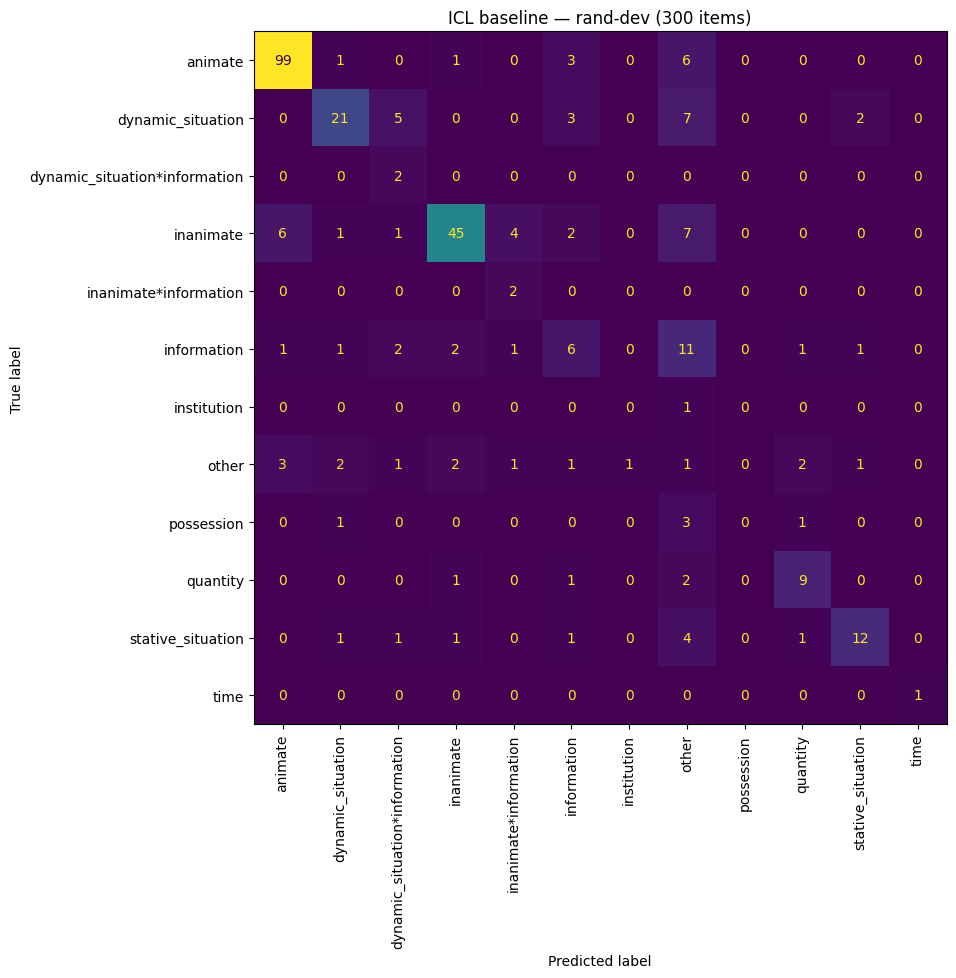

,lemma,definition,hypersense,pred,pred_no_lemma
2,coronawashing,"Procédé mercatique utilisé par un État, organi...",dynamic_situation,other,dynamic_situation*information
8,psilocybe_en_fer_de_lance,Synonyme de psilocybe lancéolé (espèce de cham...,inanimate,animate,inanimate
17,gallicanisme,Attachement à cette doctrine.,stative_situation,other,stative_situation
21,question_préjudicielle,Question qui doit être jugée avant la contesta...,dynamic_situation*information,dynamic_situation*information,dynamic_situation
22,victoriat,"Pièce de monnaie d’argent valant cinq as, à l’...",other,inanimate*information,inanimate
...,...,...,...,...,...
273,apparition_mariale,Vision miraculeuse de la Vierge Marie par une ...,dynamic_situation,dynamic_situation*information,dynamic_situation
276,agrofourniture,Ensemble des produits consommables de l’agricu...,dynamic_situation,other,inanimate
277,corépresseur,Molécule qui déclenche la répression de la tra...,inanimate,other,information
288,infodivertissement,"Même sens, utilisé pour critiquer les médias.",dynamic_situation,information,other


In [ ]:
# Confusion matrix of the baseline, and items whose
# prediction changes when the lemma is removed (same items, same order)
plot_confusion(dev_preds["baseline"], "ICL baseline — rand-dev (300 items)")

b, nl = dev_preds["baseline"], dev_preds["no_lemma"]
changed = b.assign(pred_no_lemma=nl["pred"])[b["pred"] != nl["pred"]]
changed[["lemma", "definition", "hypersense", "pred", "pred_no_lemma"]]

# Method 2: Fine-tuning

In [ ]:
# Loading the model

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# The checkpoint ships a bf16 compute dtype, which the T4 lacks, and transformers
# ignores a quantization_config we pass. So we patch the shipped one.
base_cfg = AutoConfig.from_pretrained(MODEL_NAME)
qc = base_cfg.quantization_config
if isinstance(qc, dict):
    qc["bnb_4bit_compute_dtype"] = "float16"
else:
    qc.bnb_4bit_compute_dtype = torch.float16

label2id = {lab: i for i, lab in enumerate(LABELS)}
id2label = {i: lab for lab, i in label2id.items()}

## Prepare data

In [ ]:
# Omit the long system instruction and label descriptions during fine-tuning
def to_causal(row, use_lemma):
    """Prompt/completion format: the loss is computed on the completion (label) only."""
    return {
        "prompt": [{"role": "user", "content": format_item(row, use_lemma)}],
        "completion": [{"role": "assistant", "content": row["hypersense"]}],
    }

def to_cls(row, use_lemma):
    """Tokenize the user prompt and map the gold hypersense to an integer ID for SEQ_CLS."""    msgs = [{"role": "user", "content": format_item(row, use_lemma)}]
    text = tokenizer.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
    tokens = dict(tokenizer(text, add_special_tokens=False, truncation=True, max_length=MAX_LEN))
    tokens["labels"] = label2id[row["hypersense"]]
    return tokens

def make_dataset(df, task_type, use_lemma):
    """Convert a DataFrame into a HuggingFace Dataset formatted for CAUSAL_LM or SEQ_CLS."""
    fn = to_causal if task_type == "CAUSAL_LM" else to_cls
    # remove_columns: keep only what the trainer needs
    return Dataset.from_pandas(df).map(lambda r: fn(r, use_lemma), remove_columns=list(df.columns))

## Training

In [ ]:
def free_memory():
    """Run garbage collection and clear PyTorch's CUDA cache between model runs"""
    gc.collect(); torch.cuda.empty_cache()

# Different configurations that'll be trained:
peft_configs = {
    "causal_base":      dict(task_type="CAUSAL_LM", target_modules=["q_proj", "v_proj"], use_lemma=True),
    "causal_no_lemma":  dict(task_type="CAUSAL_LM", target_modules=["q_proj", "v_proj"], use_lemma=False),  # is the lemma useful?
    "causal_wide_lora": dict(task_type="CAUSAL_LM", target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], use_lemma=True),  # more adapters?
    "cls_base":         dict(task_type="SEQ_CLS",   target_modules=["q_proj", "v_proj"], use_lemma=True),  # classification head
}

def is_trained(name):
    """Verify whether a configuration's final LoRA adapter weights have already been saved"""
    return os.path.exists(f"{OUT_DIR_PEFT}/{name}/final_weights/adapter_model.safetensors")

def run_peft_experiment(name, task_type, target_modules, use_lemma):
    """Train a QLoRA configuration for 1 epoch on the full training set and save its adapter."""
    print(f"\n--- {name} ---")
    free_memory()
    train_ds = make_dataset(train, task_type, use_lemma)
    dev_ds = make_dataset(DEV_SUB, task_type, use_lemma)

    cfg = copy.deepcopy(base_cfg)
    if task_type == "SEQ_CLS":
        cfg.num_labels = len(LABELS); cfg.id2label = id2label; cfg.label2id = label2id
        # Required by Qwen2.5 so the classification head pools the last non-padding token
        cfg.pad_token_id = tokenizer.pad_token_id
        if isinstance(cfg.quantization_config, dict):
            # avoids that the scoring head is compressed to 4bit byte tensor
            cfg.quantization_config["llm_int8_skip_modules"] = ["lm_head", "score"]
        else:
            cfg.quantization_config.llm_int8_skip_modules = ["lm_head", "score"]

    auto_cls = AutoModelForCausalLM if task_type == "CAUSAL_LM" else AutoModelForSequenceClassification
    ft_model = auto_cls.from_pretrained(MODEL_NAME, config=cfg, dtype=torch.float16, device_map={"": 0})

    ft_model = prepare_model_for_kbit_training(ft_model, use_gradient_checkpointing=True)
    ft_model = get_peft_model(ft_model, LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.05, bias="none",
        target_modules=target_modules, task_type=task_type)) # SEQ_CLS also trains the head
    ft_model.print_trainable_parameters()

    path = f"{OUT_DIR_PEFT}/{name}"
    common = dict(
        output_dir=path,
        # Batch size 8 x 2 accumulation steps = effective batch size 16 (fits within 15GB T4 VRAM)
        per_device_train_batch_size=8, gradient_accumulation_steps=2,
        learning_rate=2e-4, num_train_epochs=1,
        eval_strategy="epoch",
        logging_steps=50,
        save_strategy="no", # skip intermediate checkpoints to conserve Drive storage
        report_to="none",
        fp16=False, bf16=False, # trainable params are fp32 -> disables GradScaler (details on report)
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
    )
    if task_type == "CAUSAL_LM":
        trainer = SFTTrainer(model=ft_model, args=SFTConfig(**common, max_length=MAX_LEN, completion_only_loss=True),
                             train_dataset=train_ds, eval_dataset=dev_ds, processing_class=tokenizer)
    else:
        trainer = Trainer(model=ft_model, args=TrainingArguments(**common),
                          train_dataset=train_ds, eval_dataset=dev_ds, processing_class=tokenizer)

    trainer.train()
    trainer.save_model(f"{path}/final_weights")

    # Save the loss history
    with open(f"{path}/final_weights/log_history.json", "w") as f:
        json.dump(trainer.state.log_history, f)
    with open(f"{path}/final_weights/train_meta.json", "w") as f:
        json.dump(dict(task_type=task_type, target_modules=target_modules,
                       use_lemma=use_lemma, max_len=MAX_LEN, model=MODEL_NAME), f)

    del ft_model, trainer
    free_memory()

In [ ]:
# Free the ICL model from part 1 if it is still on the GPU (each run reloads its own copy)
try:
    del model
except NameError:
    pass
free_memory()

for name, cfg in peft_configs.items():
    if is_trained(name):
        print(f"Skipping {name}, already trained.")
        continue
    run_peft_experiment(name, **cfg)

# Force pending writes to reach Drive, then remount
drive.flush_and_unmount()
drive.mount("/content/drive")


--- causal_base ---


Map:   0%|          | 0/10604 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

trainable params: 2,523,136 || all params: 7,618,139,648 || trainable%: 0.0331


Tokenizing train dataset:   0%|          | 0/10604 [00:00<?, ? examples/s]

... (40 outputs left out)

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: unsloth/Qwen2.5-7B-Instruct-bnb-4bit
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 2,566,144 || all params: 7,073,228,288 || trainable%: 0.0363


Epoch,Training Loss,Validation Loss
1,1.143277,0.632611


Mounted at /content/drive


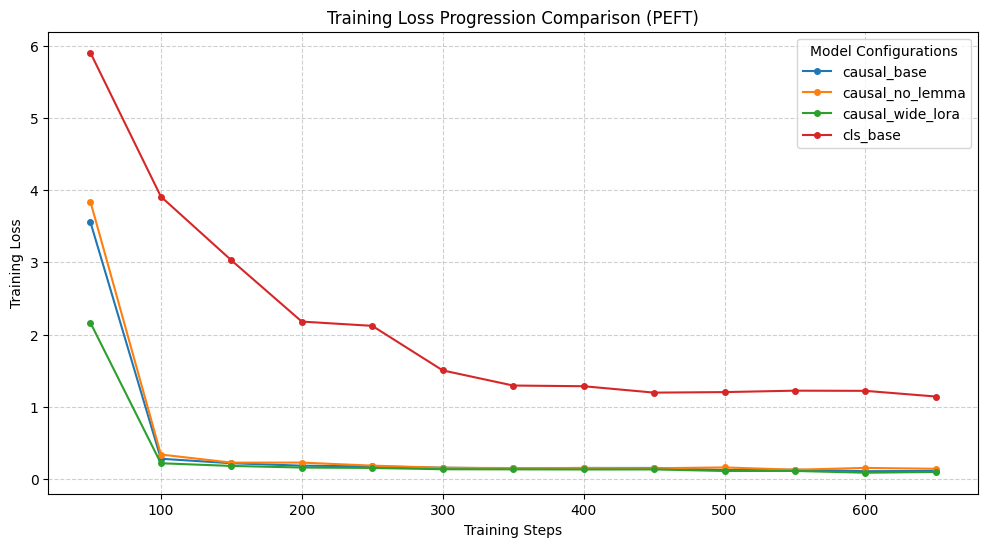

In [ ]:
# Plot training loss across optimization steps
plt.figure(figsize=(12, 6))

for name in peft_configs.keys():
    log_path = f"{OUT_DIR_PEFT}/{name}/final_weights/log_history.json"

    with open(log_path) as f:
        log_history = json.load(f)

    steps = [l["step"] for l in log_history if "loss" in l and "step" in l]
    losses = [l["loss"] for l in log_history if "loss" in l and "step" in l]
    if steps:
        plt.plot(steps, losses, label=name, marker="o", markersize=4)

plt.xlabel("Training Steps")
plt.ylabel("Training Loss")
plt.title("Training Loss Progression Comparison (PEFT)")
plt.legend(title="Model Configurations")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## Choosing best model on devset

In [ ]:
@torch.no_grad()
def evaluate_peft(data, name, task_type, use_lemma, target_modules=None, batch_size=16):
    """Load a trained PEFT adapter from Drive and evaluate it on 'data' using batched inference"""
    free_memory()
    adapter_path = f"{OUT_DIR_PEFT}/{name}/final_weights"

    cfg = copy.deepcopy(base_cfg)
    if task_type == "SEQ_CLS":
        cfg.num_labels = len(LABELS)
        cfg.id2label = id2label
        cfg.label2id = label2id
        cfg.pad_token_id = tokenizer.pad_token_id
        if isinstance(cfg.quantization_config, dict):
            cfg.quantization_config["llm_int8_skip_modules"] = ["lm_head", "score"]
        else:
            cfg.quantization_config.llm_int8_skip_modules = ["lm_head", "score"]

    auto_cls = AutoModelForCausalLM if task_type == "CAUSAL_LM" else AutoModelForSequenceClassification
    base_model = auto_cls.from_pretrained(MODEL_NAME, config=cfg, dtype=torch.float16, device_map={"": 0})
    ft_model = PeftModel.from_pretrained(base_model, adapter_path)
    ft_model.eval()

    prompts = [
        tokenizer.apply_chat_template(
            [{"role": "user", "content": format_item(row, use_lemma)}],
            add_generation_prompt=True,
            tokenize=False
        )
        for _, row in data.iterrows()
    ]

    preds = []
    # For generation, left-padding is required when batching
    orig_padding_side = tokenizer.padding_side
    tokenizer.padding_side = "left" if task_type == "CAUSAL_LM" else "right"

    try:
        for i in tqdm(range(0, len(prompts), batch_size), desc=f"Eval {name}"):
            batch_prompts = prompts[i : i + batch_size]
            inputs = tokenizer(
                batch_prompts,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=MAX_LEN,
                add_special_tokens=False
            ).to(ft_model.device)

            if task_type == "CAUSAL_LM":
                out = ft_model.generate(
                    **inputs,
                    max_new_tokens=10,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id
                )
                gen_tokens = out[:, inputs["input_ids"].shape[1]:]
                texts = tokenizer.batch_decode(gen_tokens, skip_special_tokens=True)
                for t in texts:
                    t_clean = t.strip()
                    preds.append(t_clean if t_clean in LABELS else "INVALID")
            else:
                logits = ft_model(**inputs).logits
                pred_ids = torch.argmax(logits, dim=-1).tolist()
                preds.extend([id2label[pid] for pid in pred_ids])
    finally:
        tokenizer.padding_side = orig_padding_side
        del ft_model, base_model
        free_memory()

    out_df = data.assign(pred=preds)
    return compute_metrics(out_df), out_df

In [ ]:
for name, cfg in peft_configs.items():
    pred_file = f"{OUT_DIR_PEFT}/dev_preds_{name}.csv"
    metric_file = f"{OUT_DIR_PEFT}/dev_metrics_{name}.csv"

    if os.path.exists(pred_file) and os.path.exists(metric_file):
        print(f"{name} already evaluated on dev, skipped.")
        continue

    m, out = evaluate_peft(DEV_SUB, name, **cfg)
    out.to_csv(pred_file, index=False)
    pd.DataFrame([{"config": name, **cfg, **m}]).to_csv(metric_file, index=False)
    print(name, m)

# Rank QLoRA configurations on rand-dev by macro-F1
peft_dev_results = pd.concat(
    pd.read_csv(f) for f in sorted(glob.glob(f"{OUT_DIR_PEFT}/dev_metrics_*.csv"))
).sort_values("macro_f1", ascending=False).reset_index(drop=True)

peft_dev_preds = {
    os.path.basename(f)[len("dev_preds_"):-4]: pd.read_csv(f)
    for f in glob.glob(f"{OUT_DIR_PEFT}/dev_preds_*.csv")
}

causal_base already evaluated on dev, skipped.
causal_no_lemma already evaluated on dev, skipped.
causal_wide_lora already evaluated on dev, skipped.
cls_base already evaluated on dev, skipped.


In [ ]:
peft_dev_results

,config,task_type,target_modules,use_lemma,accuracy,macro_f1,invalid_rate
0,cls_base,SEQ_CLS,"['q_proj', 'v_proj']",True,0.823333,0.601626,0.000000
1,causal_wide_lora,CAUSAL_LM,"['q_proj', 'k_proj', 'v_proj', 'o_proj']",True,0.830000,0.597478,0.000000
2,causal_base,CAUSAL_LM,"['q_proj', 'v_proj']",True,0.823333,0.593992,0.003333
3,causal_no_lemma,CAUSAL_LM,"['q_proj', 'v_proj']",False,0.820000,0.573829,0.000000


In [ ]:
# Automatically select the best configuration based on dev macro_f1
BEST_PEFT_NAME = peft_dev_results.iloc[0]["config"]
BEST_PEFT_CFG = peft_configs[BEST_PEFT_NAME]
print(f"Best PEFT configuration on dev: {BEST_PEFT_NAME}")

Best PEFT configuration on dev: cls_base


## Lemma vs no-lemma analysis

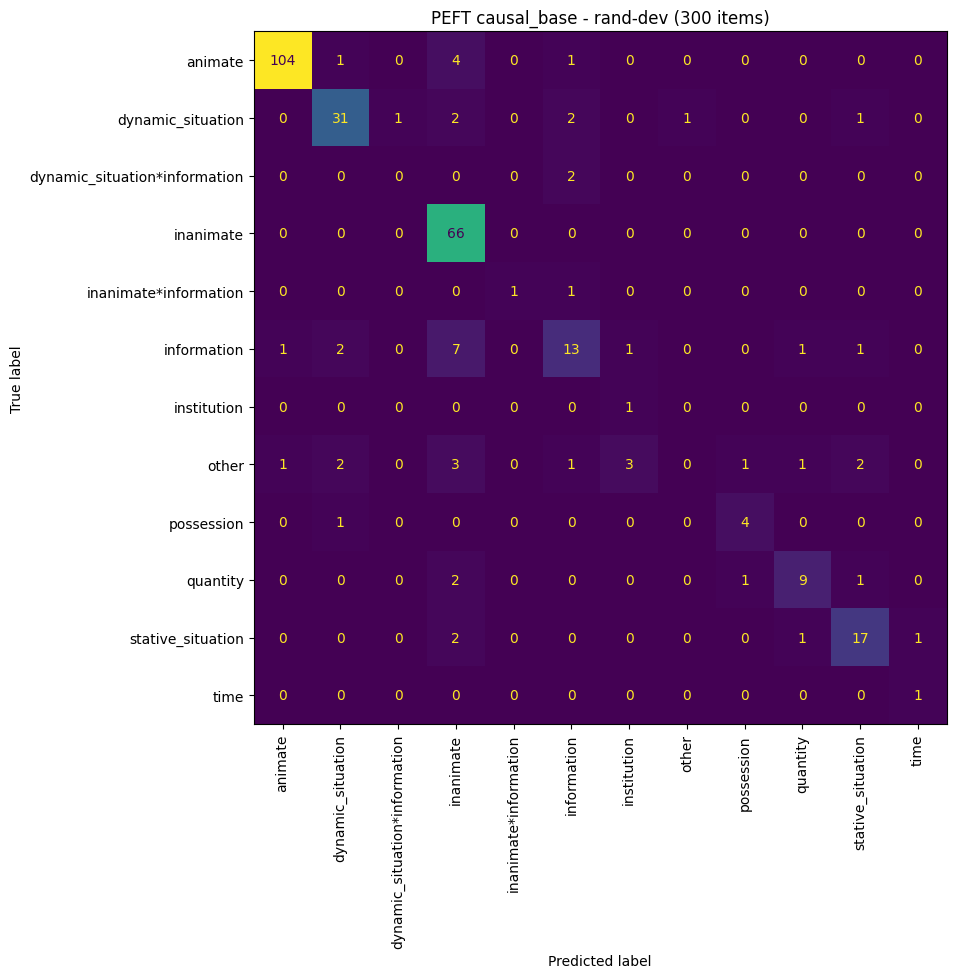

Predictions changed when removing lemma (PEFT): 29 / 300


,lemma,definition,hypersense,pred,pred_no_lemma
41,canal,Fréquence ou bande de fréquence utilisée pour ...,dynamic_situation,inanimate,quantity
48,dynamisation,"Action de dynamiser, de rendre dynamique.",other,INVALID,dynamic_situation
70,sergetterie,Sergerie.,dynamic_situation,other,dynamic_situation
91,canal,"Voie, moyen, entremise dont on se sert pour qu...",information,inanimate,information
94,champ_magnétique,Entourage.,stative_situation,inanimate,animate
95,deuxième_art,La sculpture.,information,inanimate,information
99,argus_bleu_céleste,Synonyme d’azuré bleu céleste (papillon).,animate,animate,inanimate
117,cellule,Unité morphologique ou fonctionnelle d’un ense...,information,inanimate,other
122,unité,"Groupe constitué de soldats, gendarmes ou poli...",other,animate,institution
125,bonification,"Avantage accordé à un concurrent (en points, t...",information,dynamic_situation,quantity


In [ ]:
# Inspect items whose prediction changes when removing the lemma under QLoRA fine-tuning
plot_confusion(peft_dev_preds["causal_base"], "PEFT causal_base - rand-dev (300 items)")

b_peft, nl_peft = peft_dev_preds["causal_base"], peft_dev_preds["causal_no_lemma"]
changed_peft = b_peft.assign(pred_no_lemma=nl_peft["pred"])[b_peft["pred"] != nl_peft["pred"]]
print(f"Predictions changed when removing lemma (PEFT): {len(changed_peft)} / {len(b_peft)}")
display(changed_peft[["lemma", "definition", "hypersense", "pred", "pred_no_lemma"]])

# Final evaluation

## ICL

/content/drive/MyDrive/lab1_icl/test_preds_icl_k24_freq-test.csv
       split  accuracy  macro_f1  invalid_rate
0  freq-test  0.531887  0.454405           0.0


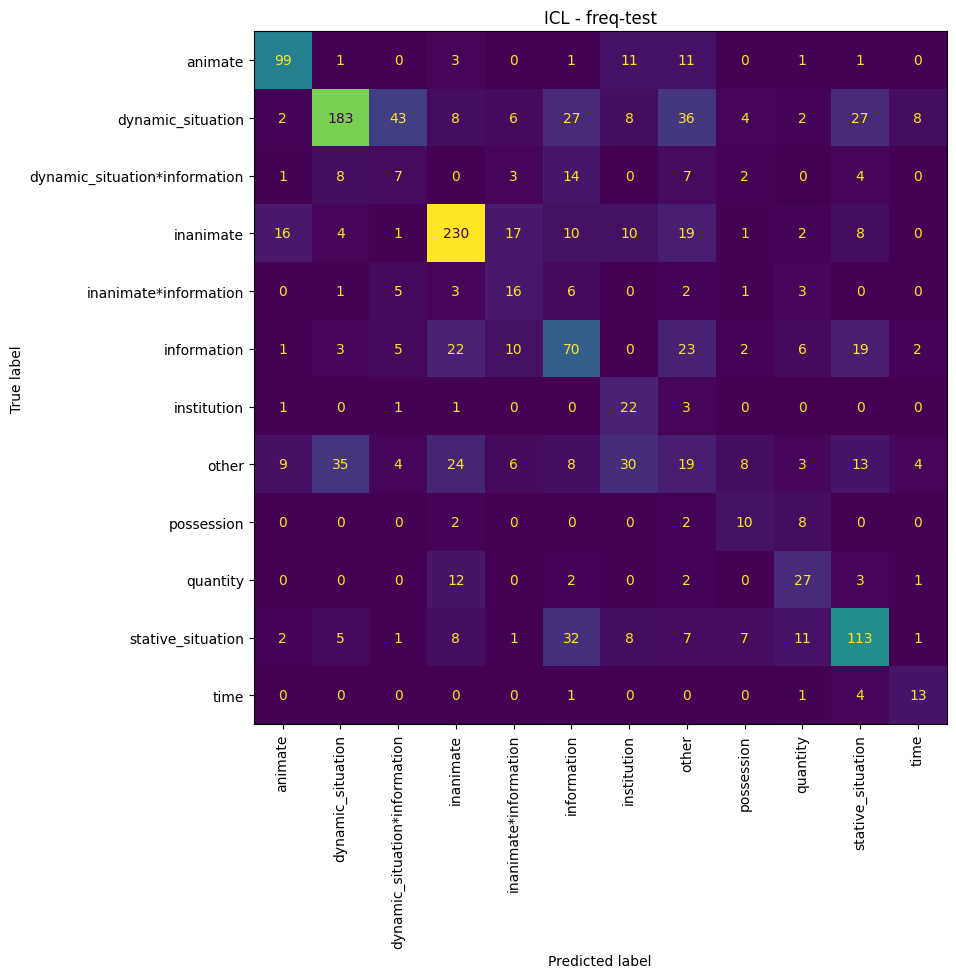

/content/drive/MyDrive/lab1_icl/test_preds_icl_k24_rand-test.csv
       split  accuracy  macro_f1  invalid_rate
0  rand-test   0.69174  0.485904           0.0


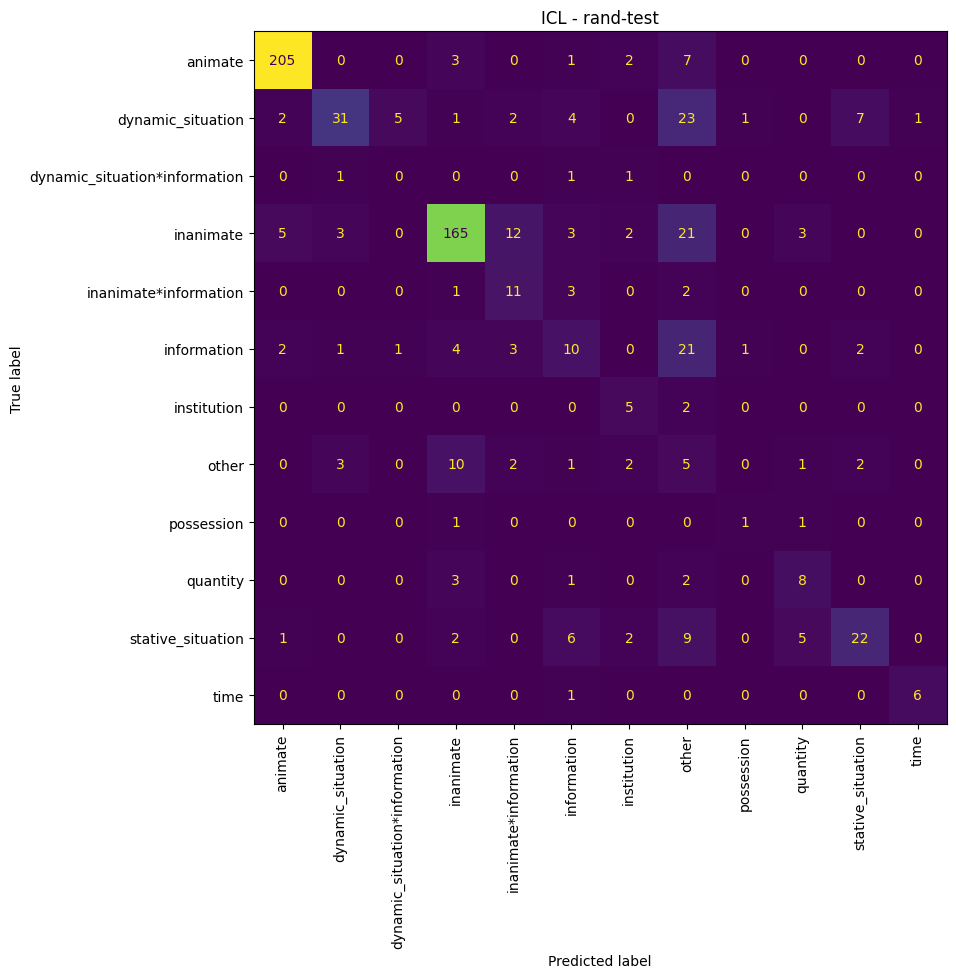

In [ ]:
# Final evaluation on the test sets: run ONCE, at the very end
test_preds = {}
for split in ["freq-test", "rand-test"]:
    f = f"{OUT_DIR}/test_preds_icl_{BEST_ICL_NAME}_{split}.csv"
    print(f)
    if not os.path.exists(f):
        # Reload the ICL base model only if it was deleted earlier and we actually need to run inference
        if "model" not in globals():
            model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map="auto", dtype=torch.float16)
            model.eval()
        m, out = evaluate(splits[split], **BEST)
        out.to_csv(f, index=False)
        pd.DataFrame([{"split": split, **m}]).to_csv(f"{OUT_DIR}/test_metrics_icl_{BEST_ICL_NAME}_{split}.csv", index=False)
    test_preds[split] = pd.read_csv(f)
    print(pd.read_csv(f"{OUT_DIR}/test_metrics_icl_{BEST_ICL_NAME}_{split}.csv"))
    plot_confusion(test_preds[split], f"ICL - {split}")

/content/drive/MyDrive/lab1_icl/test_preds_icl_baseline_freq-test.csv


  0%|          | 0/1521 [00:00<?, ?it/s]

       split  accuracy  macro_f1  invalid_rate
0  freq-test  0.526627  0.460085           0.0


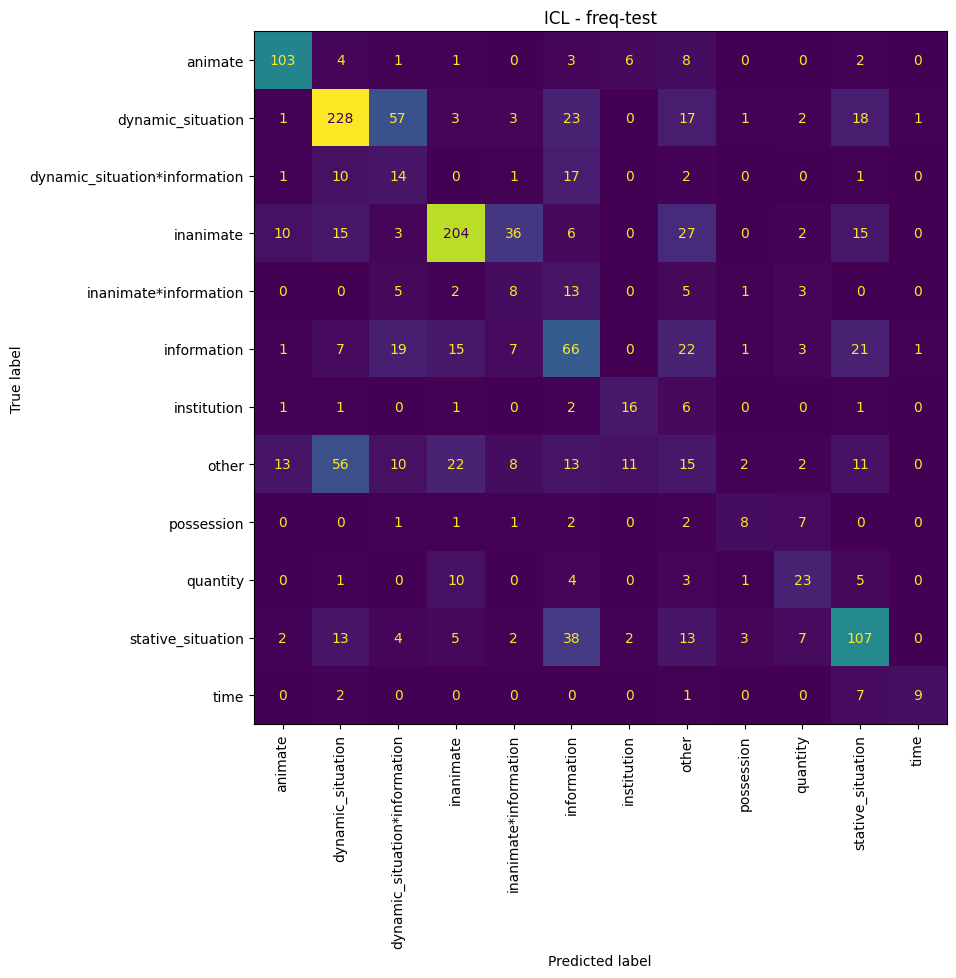

/content/drive/MyDrive/lab1_icl/test_preds_icl_baseline_rand-test.csv


  0%|          | 0/678 [00:00<?, ?it/s]

       split  accuracy  macro_f1  invalid_rate
0  rand-test  0.672566   0.47553           0.0


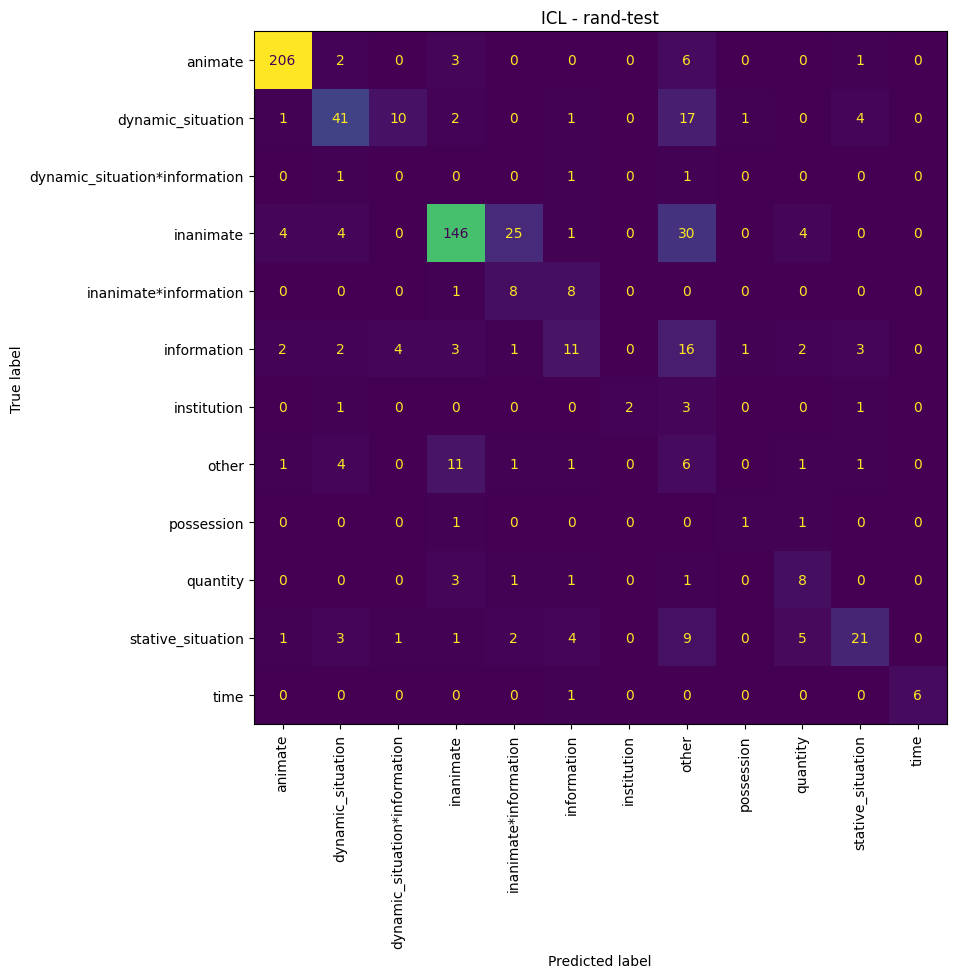

In [ ]:
# Observing baseline too
test_preds_baseline = {}
for split in ["freq-test", "rand-test"]:
    f = f"{OUT_DIR}/test_preds_icl_baseline_{split}.csv"
    print(f)
    if not os.path.exists(f):
        if "model" not in globals():
            model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map="auto", dtype=torch.float16)
            model.eval()
        m, out = evaluate(splits[split], **configs['baseline'])
        out.to_csv(f, index=False)
        pd.DataFrame([{"split": split, **m}]).to_csv(f"{OUT_DIR}/test_metrics_icl_baseline_{split}.csv", index=False)
    test_preds_baseline[split] = pd.read_csv(f)
    print(pd.read_csv(f"{OUT_DIR}/test_metrics_icl_baseline_{split}.csv"))
    plot_confusion(test_preds_baseline[split], f"ICL - {split}")

## Fine-tuning

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: unsloth/Qwen2.5-7B-Instruct-bnb-4bit
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Eval cls_base:   0%|          | 0/96 [00:00<?, ?it/s]

            method      split  accuracy  macro_f1  invalid_rate
0  PEFT (cls_base)  freq-test   0.69954  0.600154           0.0


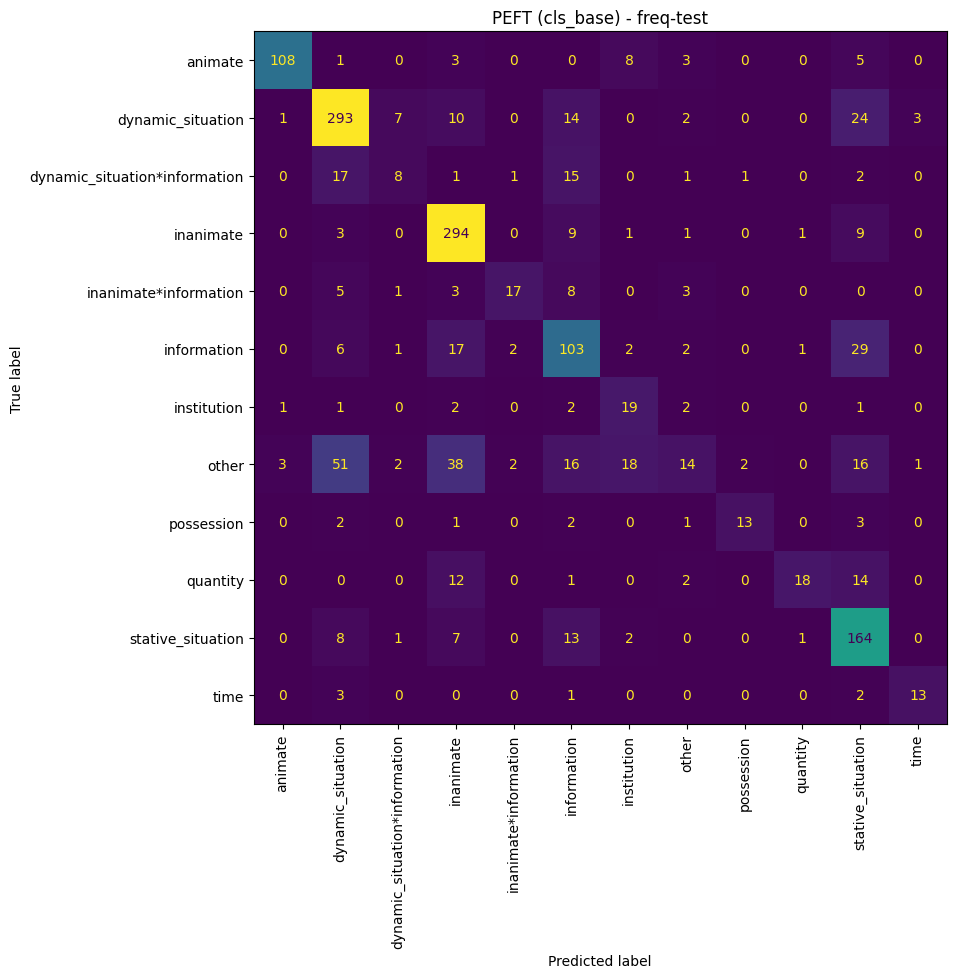

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: unsloth/Qwen2.5-7B-Instruct-bnb-4bit
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Eval cls_base:   0%|          | 0/43 [00:00<?, ?it/s]

            method      split  accuracy  macro_f1  invalid_rate
0  PEFT (cls_base)  rand-test  0.845133  0.637178           0.0


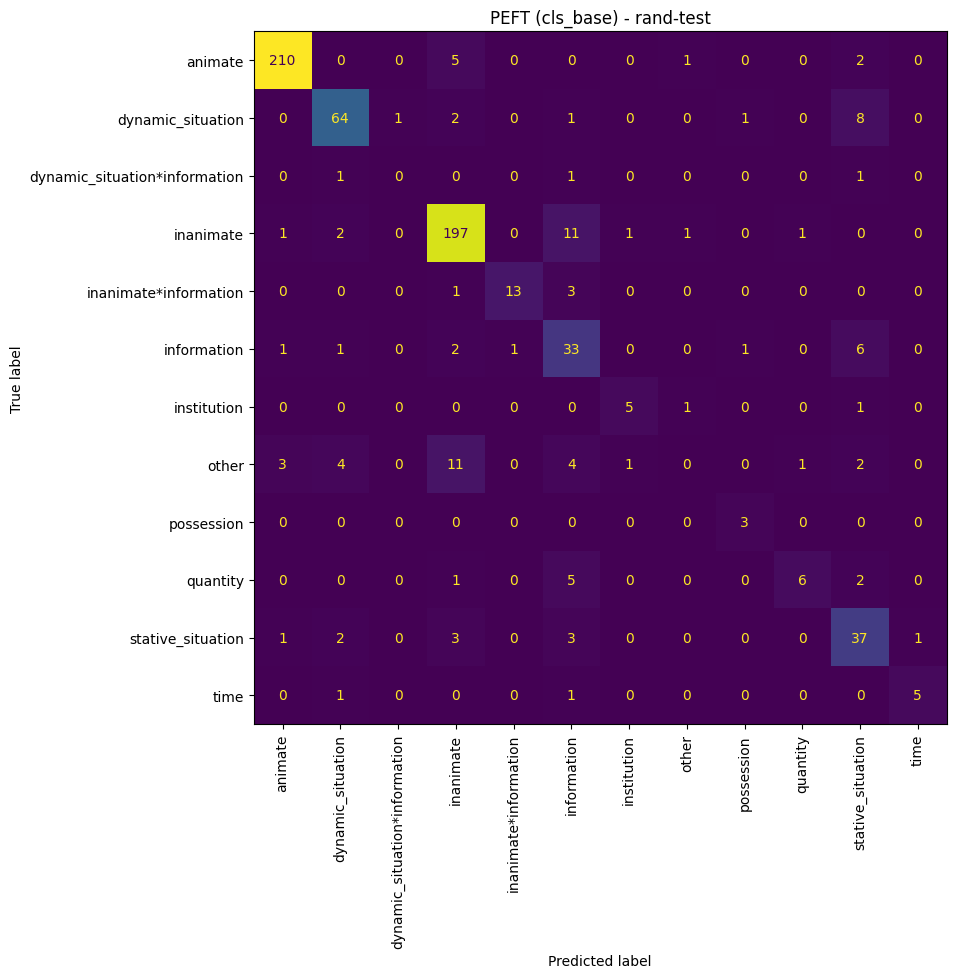

In [ ]:
# Doing the same for the fine-tuning strategy
peft_test_preds = {}
for split in ["freq-test", "rand-test"]:
    pred_file = f"{OUT_DIR_PEFT}/test_preds_peft_{split}.csv"
    metric_file = f"{OUT_DIR_PEFT}/test_metrics_peft_{split}.csv"

    if not os.path.exists(pred_file):
        m, out = evaluate_peft(splits[split], BEST_PEFT_NAME, **BEST_PEFT_CFG)
        out.to_csv(pred_file, index=False)
        pd.DataFrame([{"method": f"PEFT ({BEST_PEFT_NAME})", "split": split, **m}]).to_csv(metric_file, index=False)

    peft_test_preds[split] = pd.read_csv(pred_file)
    print(pd.read_csv(metric_file))
    plot_confusion(peft_test_preds[split], f"PEFT ({BEST_PEFT_NAME}) - {split}")

## Error analysis

,method,split,accuracy,macro_f1,invalid_rate
0,ICL,freq-test,0.532,0.454,0.0
1,ICL,rand-test,0.692,0.486,0.0
2,PEFT,freq-test,0.700,0.600,0.0
3,PEFT,rand-test,0.845,0.637,0.0



Per-class results, rand-test


ICL                              PEFT  \
                              precision recall f1-score support precision   
animate                            0.95   0.94     0.95   218.0      0.97   
dynamic_situation                  0.79   0.40     0.53    77.0      0.85   
dynamic_situation*information      0.00   0.00     0.00     3.0      0.00   
inanimate                          0.87   0.77     0.82   214.0      0.89   
inanimate*information              0.37   0.65     0.47    17.0      0.93   
information                        0.32   0.22     0.26    45.0      0.53   
institution                        0.36   0.71     0.48     7.0      0.71   
other                              0.05   0.19     0.08    26.0      0.00   
possession                         0.33   0.33     0.33     3.0      0.60   
quantity                           0.44   0.57     0.50    14.0      0.75   
stative_situation                  0.67   0.47     0.55    47.0      0.63   
time                               0.86   0.86     0.86     7.0      0.83   

                                                       
                              recall f1-score support  
animate                         0.96     0.97   218.0  
dynamic_situation               0.83     0.84    77.0  
dynamic_situation*information   0.00     0.00     3.0  
inanimate                       0.92     0.90   214.0  
inanimate*information           0.76     0.84    17.0  
information                     0.73     0.62    45.0  
institution                     0.71     0.71     7.0  
other                           0.00     0.00    26.0  
possession                      1.00     0.75     3.0  
quantity                        0.43     0.55    14.0  
stative_situation               0.79     0.70    47.0  
time                            0.71     0.77     7.0


Per-class results, freq-test


ICL                              PEFT  \
                              precision recall f1-score support precision   
animate                            0.76   0.77     0.76   128.0      0.96   
dynamic_situation                  0.76   0.52     0.62   354.0      0.75   
dynamic_situation*information      0.10   0.15     0.12    46.0      0.40   
inanimate                          0.73   0.72     0.73   318.0      0.76   
inanimate*information              0.27   0.43     0.33    37.0      0.77   
information                        0.41   0.43     0.42   163.0      0.56   
institution                        0.25   0.79     0.38    28.0      0.38   
other                              0.15   0.12     0.13   163.0      0.45   
possession                         0.29   0.45     0.35    22.0      0.81   
quantity                           0.42   0.57     0.49    47.0      0.86   
stative_situation                  0.59   0.58     0.58   196.0      0.61   
time                               0.45   0.68     0.54    19.0      0.76   

                                                       
                              recall f1-score support  
animate                         0.84     0.90   128.0  
dynamic_situation               0.83     0.79   354.0  
dynamic_situation*information   0.17     0.24    46.0  
inanimate                       0.92     0.83   318.0  
inanimate*information           0.46     0.58    37.0  
information                     0.63     0.59   163.0  
institution                     0.68     0.49    28.0  
other                           0.09     0.14   163.0  
possession                      0.59     0.68    22.0  
quantity                        0.38     0.53    47.0  
stative_situation               0.84     0.71   196.0  
time                            0.68     0.72    19.0


Top confusions: ICL, rand-test


... (13 outputs left out)

,mean,size
multiword,,
False,0.84,602
True,0.92,76


,mean,size
synonym_def,,
False,0.84,644
True,0.85,34



rand-test: both right 0.66 | only ICL 0.03 | only PEFT 0.19 | both wrong 0.12

freq-test: both right 0.47 | only ICL 0.06 | only PEFT 0.23 | both wrong 0.24


,lemma,definition,supersense,hypersense,pred,pred_peft
319,tchipage,Synonyme de tchip.,act,dynamic_situation,other,information
25,queue,"Extrémité d’une pierre longue, entrant dans la construction d’un mur ou d’une voûte.",other,other,inanimate,inanimate
590,pièce,Médaille offerte aux époux lors de la cérémonie de mariage. → voir pièce de mariage,artifact,inanimate,inanimate*information,information
485,auto-isolement,Fait pour une personne ou un groupe de personnes de se couper des autres ou du reste de la colle...,other,other,dynamic_situation,dynamic_situation
104,enchanterie,Enchantement.,other,other,dynamic_situation,dynamic_situation
473,classisme,Discrimination fondée sur la classe sociale.,cognition,information,stative_situation,stative_situation
462,découvite,Variante de découd-vite.,artifact,inanimate,other,dynamic_situation
138,pluviomètre,Ce qui enregistre les précipitations.,other,other,inanimate*information,inanimate
667,obédience,Obéissance. Note : il ne se dit ordinairement qu’en parlant des religieux.,act,dynamic_situation,other,stative_situation
550,pièce,Morceau permettant de constituer une image. → voir pièce de puzzle,artifact,inanimate,inanimate*information,information


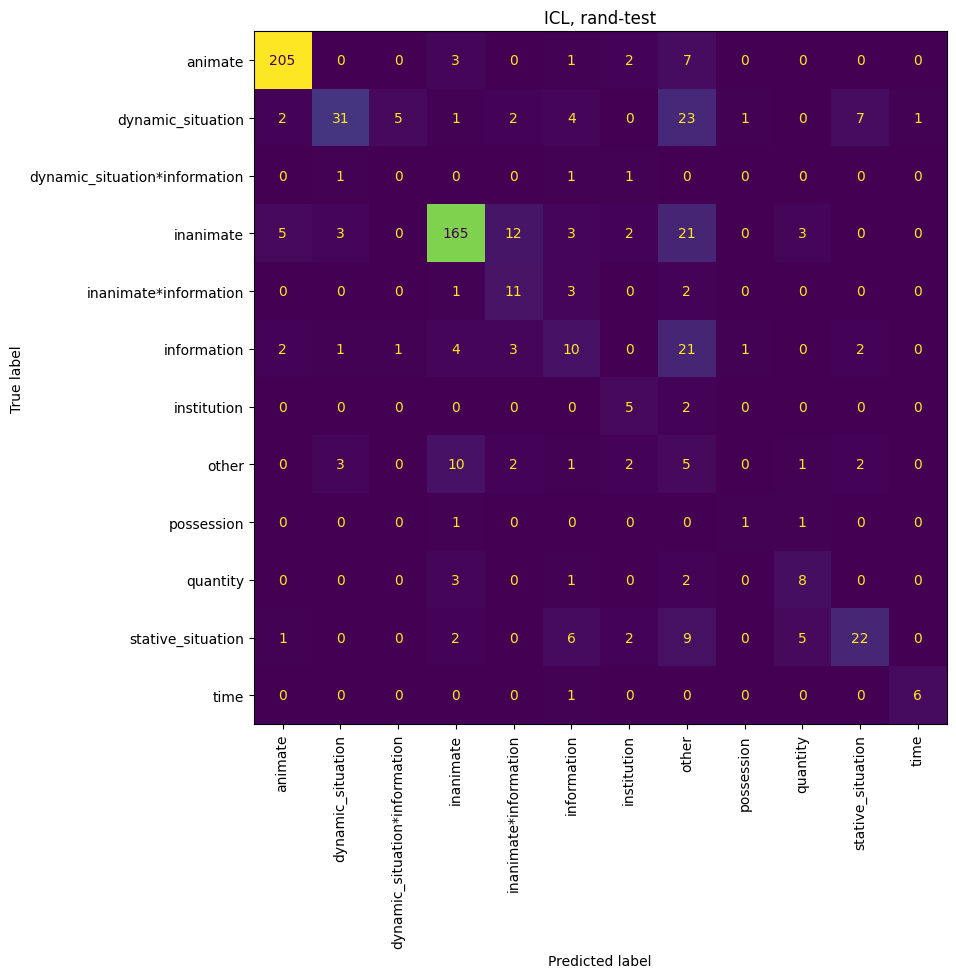

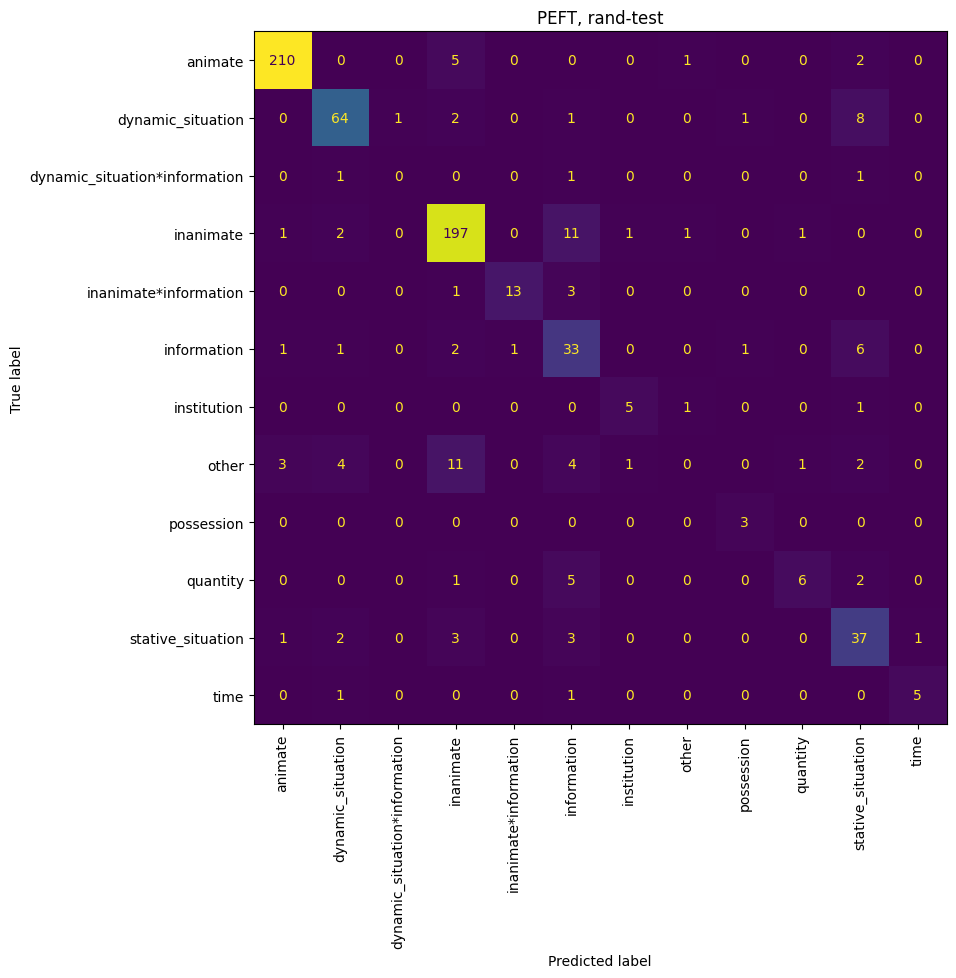

In [ ]:
methods = {"ICL": test_preds, "PEFT": peft_test_preds}

# Summary table comparing overall accuracy and macro-F1 across test splits
rows = []
for m, d in methods.items():
    for split, o in d.items():
        rows.append({"method": m, "split": split, **compute_metrics(o)})
display(pd.DataFrame(rows).round(3))

# Per-class precision/recall/F1
for split in ["rand-test", "freq-test"]:
    per_class = {}
    for m, d in methods.items():
        rep = classification_report(d[split]["hypersense"], d[split]["pred"],
                                    labels=LABELS, output_dict=True, zero_division=0)
        per_class[m] = pd.DataFrame(rep).T.loc[LABELS, ["precision", "recall", "f1-score", "support"]]
    table = pd.concat(per_class, axis=1)
    print(f"\nPer-class results, {split}")
    display(table.round(2))

def top_confusions(o, n=8):
    """Return the n most frequent (gold, predicted) error pairs in 'o'."""
    err = o[o["hypersense"] != o["pred"]]
    return (err.groupby(["hypersense", "pred"]).size()
               .sort_values(ascending=False).head(n).rename("count").reset_index())

# Identify primary confusion patterns
for m, d in methods.items():
    print(f"\nTop confusions: {m}, rand-test")
    display(top_confusions(d["rand-test"]))

# Finer granularity: accuracy per supersense
for m, d in methods.items():
    o = d["rand-test"].assign(correct=lambda x: x["hypersense"] == x["pred"])
    print(f"\nAccuracy per supersense: {m}, rand-test")
    display(o.groupby("supersense")["correct"].agg(["mean", "size"])
              .sort_values("mean").round(2))

# Item features vs. errors
def add_features(o):
    o = o.copy()
    o["correct"] = o["hypersense"] == o["pred"]
    o["def_len"] = pd.cut(o["definition"].str.split().str.len(),
                          [0, 3, 8, 15, 1000], labels=["1-3", "4-8", "9-15", "16+"])
    o["multiword"] = o["lemma"].str.contains("_")
    o["synonym_def"] = o["definition"].str.match(r"^(Synonyme|Même sens|Variante|Abréviation)", case=False)
    return o

# Evaluate accuracy across definition length, multiword lemmas, and uninformative synonym definitions
for m, d in methods.items():
    o = add_features(d["rand-test"])
    print(f"\nAccuracy by item feature: {m}, rand-test")
    for feat in ["def_len", "multiword", "synonym_def"]:
        display(o.groupby(feat, observed=True)["correct"].agg(["mean", "size"]).round(2))

# ICL vs PEFT agreement
for split in ["rand-test", "freq-test"]:
    a, b = test_preds[split], peft_test_preds[split]
    ca, cb = a["hypersense"] == a["pred"], b["hypersense"] == b["pred"]
    print(f"\n{split}: both right {(ca & cb).mean():.2f} | only ICL {(ca & ~cb).mean():.2f} | "
          f"only PEFT {(~ca & cb).mean():.2f} | both wrong {(~ca & ~cb).mean():.2f}")

# Qualitative sample: errors BOTH methods make
a, b = test_preds["rand-test"], peft_test_preds["rand-test"]
both_wrong = a[(a["hypersense"] != a["pred"]) & (b["hypersense"] != b["pred"])].copy()
both_wrong["pred_peft"] = b.loc[both_wrong.index, "pred"]
pd.set_option("display.max_colwidth", 100)
display(both_wrong.sample(min(25, len(both_wrong)), random_state=0)
        [["lemma", "definition", "supersense", "hypersense", "pred", "pred_peft"]])

# Confusion matrices
for m, d in methods.items():
    plot_confusion(d["rand-test"], f"{m}, rand-test")